# Overview
This notebook identifies significant r values
* fisherZ correct
* stack across participants and runs
* run t-test and identify r values greater than 0
* reconvert fisherZ back to correlation coefficients
* stack coefficients across hemisphere for multiple comparisons
* save results in corresponding hemisphere while preserving medial/non-medial wall vertices

### modules

In [90]:
import numpy as np
import pandas as pd
import os, re
from os.path import join
import scipy.stats
from statsmodels.stats.multitest import multipletests
import nibabel as nib
from pathlib import Path


### function: write_gifti

In [91]:
def write_gifti_v2(data, output_fn, template_fn):
    gii = nib.load(template_fn)
    for i in np.arange(gii.numDA):
        gii.remove_gifti_data_array(0)
    gda = nib.gifti.GiftiDataArray(data)
    gii.add_gifti_data_array(gda)
    # nib.gifti.write(gii, output_fn)
    gii.to_filename(output_fn)

### parameters

In [92]:
suma_dir = '/dartfs/rc/lab/H/HaxbyLab/heejung/data/niml'# '/Users/h/suma-fsaverage6'
FEATURE = 'actions-agents-objects-moten'
main_dir = f'/dartfs/rc/lab/H/HaxbyLab/heejung/results/revision/glove_nested/{FEATURE}/ws_pca-40'
results_dir = os.path.join(main_dir )#'results', 'himalaya', "glove")
alignment = 'ws' #'ha_common'
results = [ 'scenes-r', 'agents-r','actions-r', 'objects-r', 'moten-r']
runs = [1, 2, 3, 4]
hemis = ['lh', 'rh']
pca_comp = 40
fmri_durs = {1: 374, 2: 346, 3: 377, 4: 412}
n_samples = 1509
n_vertices = 40962
n_medial = {'lh': 3486, 'rh': 3491}
unique_keys = [
    re.search(r'sub-\d+', p.name).group()
    for p in Path(results_dir).glob('*.npy')
    if p.is_file() and re.search(f'sub-\d+', p.name)
]

# subjects = Path(result_dir).rglob('*sub-*.npy')
subjects = sorted(list(set(unique_keys)))



# Run locally

# plot results in fslr

plot t-test results in surfplots, Freesurfer surface plots

In [93]:
from neuromaps.datasets import fetch_fsaverage, fetch_fslr
import numpy as np
from surfplot import Plot
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib import colors
from os.path import join
import nibabel as nib
surfaces = fetch_fsaverage()
lh, rh = surfaces['inflated']
main_dir = '/Volumes/life-encoding'
# main_dir = '/Users/h/Downloads'
alignment = 'ws'

In [94]:
def fsaverage_to_fslr_and_plot(Lfname, Rfname, key, cmap='inferno', max=.20):
    from neuromaps.datasets import fetch_fslr
    from neuromaps.transforms import fsaverage_to_fslr
    giiL = nib.load(Lfname)
    giiR = nib.load(Rfname)
    L_fslr = fsaverage_to_fslr(giiL, target_density='32k', hemi='L', method='linear')
    R_fslr = fsaverage_to_fslr(giiR, target_density='32k', hemi='R', method='linear')
    
    surfaces_fslr = fetch_fslr()
    lh_fslr, rh_fslr = surfaces_fslr['inflated']

    color_range = (0.0001, max)
    p = Plot(surf_lh=lh_fslr, 
             surf_rh=rh_fslr, 
             size=(1000, 200), 
             zoom=1.2, layout='row', 
             views=['lateral', 'medial', 'ventral', 'posterior'], 
             mirror_views=True, brightness=.7)
    p.add_layer({'left': L_fslr[0], 
                'right': R_fslr[0]}, 
                cmap=cmap, cbar=True,
                color_range=color_range,
                cbar_label=key
                ) # YlOrRd_r
    cbar_kws = dict(outer_labels_only=True, pad=.02, n_ticks=2, decimals=3)
    fig = p.build(cbar_kws=cbar_kws)
    # fig.show()
    return(fig)


In [95]:
import os
import shutil
from neuromaps import datasets

# 1. Force delete the entire atlas directory
atlas_path = '/Users/h/neuromaps-data/atlases/fsaverage'
if os.path.exists(atlas_path):
    print(f"Removing corrupted directory: {atlas_path}")
    shutil.rmtree(atlas_path)

# 2. Re-download
print("Attempting fresh download...")
datasets.fetch_atlas('fsaverage', density='41k')

# 3. Inspect the file content immediately
target_file = os.path.join(atlas_path, 'tpl-fsaverage_den-41k_hemi-L_sphere.surf.gii')

if os.path.exists(target_file):
    with open(target_file, 'r', errors='ignore') as f:
        first_line = f.readline()
        print(f"\nFile Header Check: {first_line[:50]}")
        
        if "<?xml" in first_line:
            print("✅ SUCCESS: Found valid XML header.")
        elif "<!DOCTYPE html" in first_line or "<html" in first_line:
            print("❌ FAILURE: Downloaded an HTML error page instead of data.")
        else:
            print("❌ FAILURE: Unknown file format or empty file.")

Removing corrupted directory: /Users/h/neuromaps-data/atlases/fsaverage
Attempting fresh download...


Downloaded 991232 of 6550379 bytes (15.1%,    5.8s remaining)


File Header Check: <?xml version="1.0" encoding="UTF-8"?>

✅ SUCCESS: Found valid XML header.


 ...done. (5 seconds, 0 min)
Extracting data from /Users/h/neuromaps-data/9e29c30a00cc86995f334ba48854d362/fsaverage41k.tar.gz..... done.


In [96]:
folders = {
    'actions-agents-objects-moten': 'scenes',    # missing scenes
    'scenes-actions-agents-objects': 'moten',    # missing moten
    'scenes-agents-objects-moten':   'actions',  # missing actions
    'scenes-actions-agents-moten':   'objects',  # missing objects
    'scenes-actions-objects-moten':  'agents',   # missing agents
}

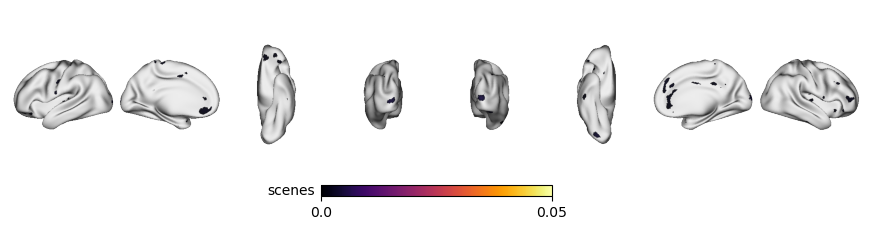

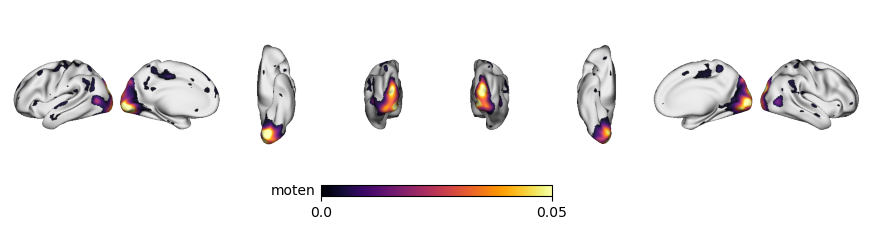

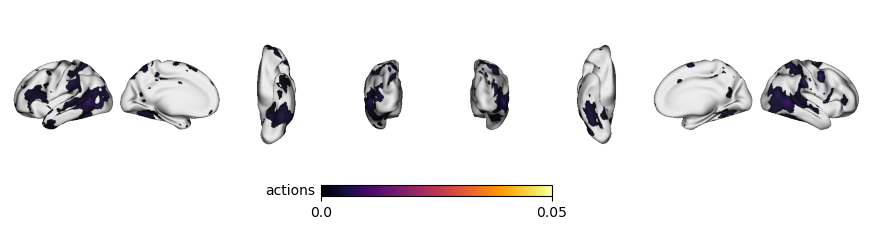

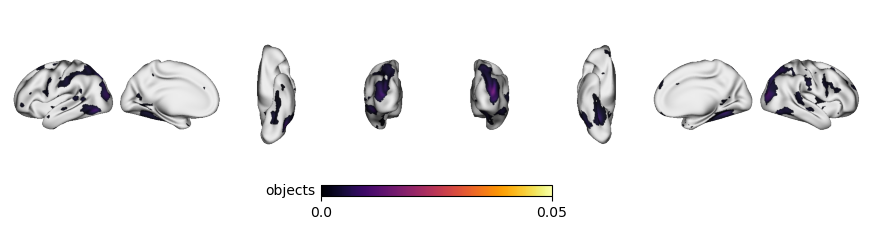

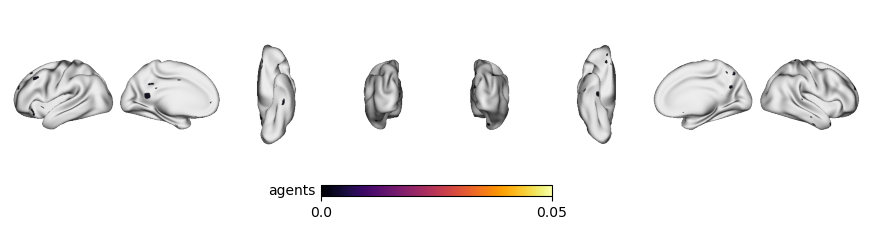

In [97]:
alignment = 'ws'

results_dir = '/Volumes/results/revision/glove_nested'
save_dir = '/Users/h/Documents/projects_local/life-encoding/figure/revision'
Path(save_dir).mkdir(parents=True, exist_ok=True)
# main_dir = 'variancepart/variance-r_objects_pca-40_align-ws_hemi-lh_ttest.gii'
# ['bg', 'agents', 'actions', 'moten']
# for folder in ['scenes', 'agents', 'actions', 'objects', 'moten']:
for folder, feature in folders.items():
    output_dir = os.path.join(results_dir, f"{folder}")
    gii_dir = join(output_dir, 'variancepart')
# for feature in ['scenes', 'agents', 'actions', 'objects', 'moten']:
    # TMP: download locally
    # gii_dir = '/Users/h/Downloads'
    bgLfname = f"{gii_dir}/variance-r_{feature}_pca-40_align-ws_hemi-lh_multcomp-unc_ttest.gii"
    bgRfname = f"{gii_dir}/variance-r_{feature}_pca-40_align-ws_hemi-rh_multcomp-unc_ttest.gii"
    
    fig = fsaverage_to_fslr_and_plot(bgLfname, bgRfname, feature, cmap='inferno', max=.05)
 
    fig.savefig(join(save_dir, f"{feature}-r_pca-40_align-{alignment}_hemi-lh_ttest_unc.png"), dpi=300)

## count significant voxels
How many voxels are significant per stat map (uncorrected)?

In [98]:
results_dir

'/Volumes/results/revision/glove_nested'

In [99]:
alignment = 'ws'
# ['bg', 'agents', 'actions', 'moten']
# for feature in ['scenes', 'agents', 'actions', 'objects', 'moten']:
for folder, feature in folders.items():
# feature = 'bg'
    output_dir = os.path.join(results_dir,folder)#f"{feature}-r")
    gii_dir = join(output_dir, 'variancepart')#'stats')
    Lfname = f"{gii_dir}/variance-r_{feature}_pca-40_align-{alignment}_hemi-lh_multcomp-unc_ttest.gii"
    Rfname = f"{gii_dir}/variance-r_{feature}_pca-40_align-{alignment}_hemi-rh_multcomp-unc_ttest.gii"


    # fsaverage_to_fslr_and_plot(bgLfname, bgRfname, feature, cmap='inferno', max=.2)

    giiL = nib.load(Lfname)
    giiR = nib.load(Rfname)

    sig_voxel = np.sum(giiL.agg_data() > 0) + np.sum(giiR.agg_data() > 0) 
    print(f"{feature}: {sig_voxel}")


scenes: 1893
moten: 13403
actions: 15702
objects: 10361
agents: 765


# cluster thresholded

We threshold the maps using work bench. The output is a (semi) boolean mask, thereby, we apply the mask back onto the t-test maps. 
Steps include
* Workbench cluster threshold
* multiply workbench mask with t-test maps
* plot thresholded maps

### workbench cluster threshold

In [100]:
results_dir

'/Volumes/results/revision/glove_nested'

In [101]:
from subprocess import call
# parameteres
hemis = ['lh', 'rh']
features = ['scenes', 'agents', 'actions', 'objects', 'moten']
clustersize = 50
hemi_dict = {'lh': 'L', 'rh': 'R'}
fsaverage_dir = '/Users/h/neuromaps-data/atlases/fsaverage'


# thresholding via workbench
for hemi in hemis:
    # for feature in features:
    for folder, feature in folders.items():
        output_dir = os.path.join(results_dir, folder) #f"{feature}-r")
        gii_dir = join(output_dir,'variancepart')#'stats')
        fsaverage_template = f"{fsaverage_dir}/tpl-fsaverage_den-41k_hemi-{hemi_dict[hemi]}_inflated.surf.gii"
        himalaya = f"{gii_dir}/variance-r_{feature}_pca-40_align-{alignment}_hemi-{hemi}_multcomp-unc_ttest.gii"
        outputfname = f"{gii_dir}/variance-r_{feature}_pca-40_align-{alignment}_hemi-{hemi}_multcomp-unc_ttest_cluster-{clustersize}.gii"
        return_code = call(f"wb_command -metric-find-clusters {fsaverage_template} {himalaya} 0 {clustersize} {outputfname}", shell=True)
print(f"Return: {return_code}")

Return: 0


In [102]:
gii_dir

'/Volumes/results/revision/glove_nested/scenes-actions-objects-moten/variancepart'

# Voxel counts

In [ ]:
save_dir = '/Users/h/Documents/projects_local/life-encoding/figure/revision'
Path(save_dir).mkdir(parents=True, exist_ok=True)
# for feature in['scenes', 'agents', 'actions', 'objects', 'moten']:
for folder, feature in folders.items():
    # output_dir = os.path.join(results_dir,f"{feature}-r")
    # gii_dir = join(output_dir, 'stats')
    output_dir = os.path.join(results_dir, folder) #f"{feature}-r")
    gii_dir = join(output_dir,'variancepart')#'stats')
    thresL = f"{gii_dir}/variance-r_{feature}_pca-40_align-ws_hemi-lh_multcomp-unc_ttest_thres-cluster{clustersize}.gii"
    thresR = f"{gii_dir}/variance-r_{feature}_pca-40_align-ws_hemi-lh_multcomp-unc_ttest_thres-cluster{clustersize}.gii"
    
    giiL = nib.load(thresL)
    giiR = nib.load(thresR)

    sig_voxel = np.sum(giiL.agg_data() > 0) + np.sum(giiR.agg_data() > 0) 
    print(f"{feature}: {sig_voxel}")


scenes: 984
moten: 14502
actions: 16776
objects: 9802
agents: 576
